# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import AveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


True

# Importamos los datos

In [4]:
path = '../../../data/noisy/Campo 100 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')
campvectrain = np.transpose(campvectrain, (0,2,3,1))

In [6]:
np.shape(campvectrain)

(7000, 100, 100, 2)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')
campvectest = np.transpose(campvectest, (0,2,3,1))

In [10]:
np.shape(campvectest)

(2000, 100, 100, 2)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(2000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')
campvecval = np.transpose(campvecval, (0,2,3,1))

In [14]:
np.shape(campvecval)

(1000, 100, 100, 2)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(1000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(100, 100, 2), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [21]:
model = Sequential()
# Primera capa convolucional
model.add(Conv2D(50, (5, 5), activation='tanh', input_shape=(100, 100, 2),kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Segunda capa convolucional
model.add(Conv2D(24, (5, 5), activation='tanh',kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001) ))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Tercera capa convolucional
model.add(Conv2D(11, (5, 5), activation='tanh',kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(50, (5, 5), activation='tanh',kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))


model.add(Flatten())

model.add(Dense(200, activation='tanh', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(100, activation='tanh', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(50,activation = 'relu', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(7, activation= custom_activation))


In [22]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(56, (4, 5), activation='tanh',input_shape=(100, 100, 2), kernel_initializer='random_normal', kernel_regularizer=l1()))
model.add(MaxPooling2D())  # MaxPooling

# Segunda capa convolucional
model.add(Conv2D(21, (4, 3), activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2()))
model.add(MaxPooling2D())  # MaxPooling

# Tercera capa convolucional
model.add(Conv2D(60, (4, 5), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1()))

# Aplanar para capas densas
model.add(Flatten())

# Capa densa
model.add(Dense(110, activation='sigmoid', kernel_initializer='HeNormal', kernel_regularizer=l2()))

model.add(Dense(110, activation='sigmoid', kernel_initializer='HeNormal', kernel_regularizer=l2()))


model.add(Dense(7, activation=custom_activation))


# Resumen del modelo
model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 97, 96, 56)        2296      
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 48, 48, 56)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 45, 46, 21)        14133     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 22, 23, 21)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 19, 19, 60)        25260     
                                                                 
 flatten_1 (Flatten)         (None, 21660)            

In [23]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 97, 96, 56)        2296      
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 48, 48, 56)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 45, 46, 21)        14133     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 22, 23, 21)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 19, 19, 60)        25260     
                                                                 
 flatten_1 (Flatten)         (None, 21660)            

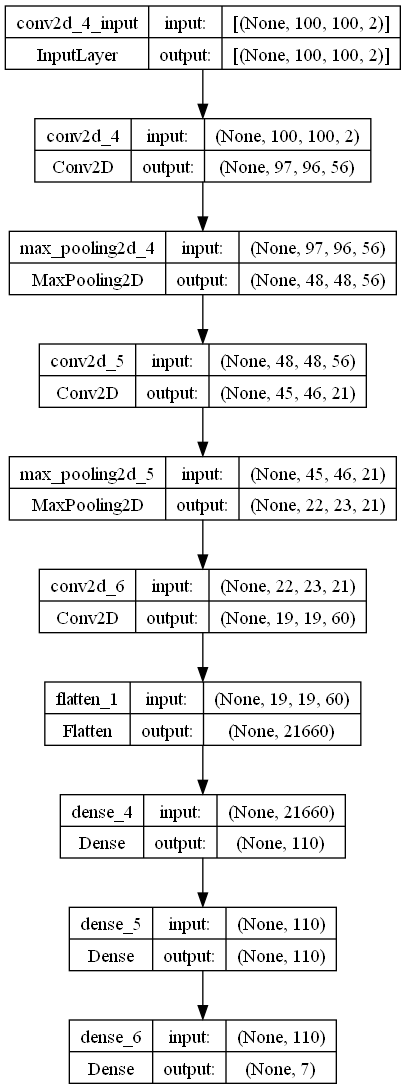

In [24]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [25]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [26]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [27]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [28]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [29]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 4s 49ms/step - loss: 12.5137 - a_1: 2.4778 - a_2: 2.4617 - b_1: 2.0966 - b_2: 2.1039 - d_1: 1.4572 - d_2: 1.4654 - n: 1.2365 - mean_metric: 0.4133 - val_loss: 7.8653 - val_a_1: 2.3987 - val_a_2: 2.3826 - val_b_1: 1.5318 - val_b_2: 1.4742 - val_d_1: 1.0563 - val_d_2: 1.1189 - val_n: 1.1873 - val_mean_metric: 0.3518 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 3s 46ms/step - loss: 6.7293 - a_1: 2.1364 - a_2: 2.2411 - b_1: 1.4108 - b_2: 1.4076 - d_1: 1.0505 - d_2: 1.0490 - n: 1.2177 - mean_metric: 0.3268 - val_loss: 5.9888 - val_a_1: 1.9699 - val_a_2: 2.0578 - val_b_1: 1.4362 - val_b_2: 1.3277 - val_d_1: 1.0366 - val_d_2: 1.0707 - val_n: 1.1545 - val_mean_metric: 0.3172 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 3s 46ms/step - loss: 5.4099 - a_1: 1.7912 - a_2: 1.8991 - b_1: 1.3089 - b_2: 1.2855 - d_1: 0.9905 - d_2: 0.9902 - n: 1.1781 - mean_metric: 0.2935 - val_loss: 5.0834 - val_a_1: 1.746

70/70 [==============================] - 3s 46ms/step - loss: 2.2334 - a_1: 1.0578 - a_2: 1.0564 - b_1: 0.8996 - b_2: 0.9017 - d_1: 0.7820 - d_2: 0.7787 - n: 0.7199 - mean_metric: 0.1927 - val_loss: 2.2579 - val_a_1: 1.0460 - val_a_2: 1.0423 - val_b_1: 0.9014 - val_b_2: 0.8945 - val_d_1: 0.7770 - val_d_2: 0.8041 - val_n: 0.7151 - val_mean_metric: 0.1952 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 3s 46ms/step - loss: 2.2221 - a_1: 1.0706 - a_2: 1.0520 - b_1: 0.8875 - b_2: 0.9027 - d_1: 0.7614 - d_2: 0.7773 - n: 0.7026 - mean_metric: 0.1914 - val_loss: 2.3049 - val_a_1: 1.0667 - val_a_2: 1.0606 - val_b_1: 0.9290 - val_b_2: 0.9030 - val_d_1: 0.7842 - val_d_2: 0.8260 - val_n: 0.6943 - val_mean_metric: 0.1978 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 3s 46ms/step - loss: 2.2208 - a_1: 1.0597 - a_2: 1.0451 - b_1: 0.8912 - b_2: 0.9066 - d_1: 0.7655 - d_2: 0.7843 - n: 0.7071 - mean_metric: 0.1915 - val_loss: 2.2976 - val_a_1: 1.0709 - val_a_2:

70/70 [==============================] - 3s 46ms/step - loss: 1.9625 - a_1: 0.9657 - a_2: 0.9860 - b_1: 0.8539 - b_2: 0.8543 - d_1: 0.7519 - d_2: 0.7668 - n: 0.5553 - mean_metric: 0.1784 - val_loss: 2.0088 - val_a_1: 0.9635 - val_a_2: 0.9896 - val_b_1: 0.8534 - val_b_2: 0.8458 - val_d_1: 0.7443 - val_d_2: 0.7836 - val_n: 0.5777 - val_mean_metric: 0.1819 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.9326 - a_1: 0.9567 - a_2: 0.9592 - b_1: 0.8508 - b_2: 0.8527 - d_1: 0.7392 - d_2: 0.7454 - n: 0.5474 - mean_metric: 0.1757 - val_loss: 2.0522 - val_a_1: 1.0262 - val_a_2: 0.9979 - val_b_1: 0.8663 - val_b_2: 0.8437 - val_d_1: 0.7523 - val_d_2: 0.7746 - val_n: 0.6136 - val_mean_metric: 0.1855 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.9646 - a_1: 0.9731 - a_2: 0.9815 - b_1: 0.8526 - b_2: 0.8559 - d_1: 0.7544 - d_2: 0.7611 - n: 0.5489 - mean_metric: 0.1781 - val_loss: 2.0083 - val_a_1: 0.9645 - val_a_2:

70/70 [==============================] - 3s 46ms/step - loss: 1.8570 - a_1: 0.9360 - a_2: 0.9642 - b_1: 0.8298 - b_2: 0.8375 - d_1: 0.7453 - d_2: 0.7382 - n: 0.4945 - mean_metric: 0.1725 - val_loss: 1.8871 - val_a_1: 0.9186 - val_a_2: 0.9813 - val_b_1: 0.8205 - val_b_2: 0.8317 - val_d_1: 0.7316 - val_d_2: 0.7565 - val_n: 0.5025 - val_mean_metric: 0.1750 - lr: 9.7140e-04
Epoch 128/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.8475 - a_1: 0.9418 - a_2: 0.9577 - b_1: 0.8221 - b_2: 0.8241 - d_1: 0.7435 - d_2: 0.7394 - n: 0.4942 - mean_metric: 0.1717 - val_loss: 1.9233 - val_a_1: 0.9190 - val_a_2: 1.0254 - val_b_1: 0.8369 - val_b_2: 0.8314 - val_d_1: 0.7466 - val_d_2: 0.7655 - val_n: 0.5243 - val_mean_metric: 0.1783 - lr: 9.7030e-04
Epoch 129/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.8236 - a_1: 0.9205 - a_2: 0.9443 - b_1: 0.8210 - b_2: 0.8287 - d_1: 0.7333 - d_2: 0.7433 - n: 0.4838 - mean_metric: 0.1702 - val_loss: 1.9259 - val_a_1: 0.9369 

70/70 [==============================] - 3s 46ms/step - loss: 1.7658 - a_1: 0.9113 - a_2: 0.8972 - b_1: 0.8098 - b_2: 0.8175 - d_1: 0.7525 - d_2: 0.7494 - n: 0.4484 - mean_metric: 0.1675 - val_loss: 1.8205 - val_a_1: 0.9072 - val_a_2: 0.9206 - val_b_1: 0.8108 - val_b_2: 0.8219 - val_d_1: 0.7599 - val_d_2: 0.7547 - val_n: 0.4616 - val_mean_metric: 0.1717 - lr: 9.2520e-04
Epoch 170/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.7803 - a_1: 0.9093 - a_2: 0.9085 - b_1: 0.8135 - b_2: 0.8247 - d_1: 0.7451 - d_2: 0.7489 - n: 0.4750 - mean_metric: 0.1687 - val_loss: 1.9199 - val_a_1: 0.9475 - val_a_2: 0.9304 - val_b_1: 0.8761 - val_b_2: 0.8308 - val_d_1: 0.8130 - val_d_2: 0.8346 - val_n: 0.4806 - val_mean_metric: 0.1805 - lr: 9.2410e-04
Epoch 171/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.7774 - a_1: 0.9221 - a_2: 0.9333 - b_1: 0.8068 - b_2: 0.8183 - d_1: 0.7262 - d_2: 0.7347 - n: 0.4645 - mean_metric: 0.1681 - val_loss: 1.8346 - val_a_1: 0.9208 

70/70 [==============================] - 3s 46ms/step - loss: 1.7184 - a_1: 0.8958 - a_2: 0.8944 - b_1: 0.8001 - b_2: 0.8123 - d_1: 0.7326 - d_2: 0.7396 - n: 0.4321 - mean_metric: 0.1650 - val_loss: 1.7653 - val_a_1: 0.8891 - val_a_2: 0.9066 - val_b_1: 0.8158 - val_b_2: 0.8074 - val_d_1: 0.7401 - val_d_2: 0.7479 - val_n: 0.4349 - val_mean_metric: 0.1687 - lr: 8.7900e-04
Epoch 212/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.6755 - a_1: 0.8511 - a_2: 0.8968 - b_1: 0.7770 - b_2: 0.7886 - d_1: 0.7226 - d_2: 0.7148 - n: 0.4370 - mean_metric: 0.1613 - val_loss: 1.7663 - val_a_1: 0.8611 - val_a_2: 0.9266 - val_b_1: 0.8175 - val_b_2: 0.8145 - val_d_1: 0.7347 - val_d_2: 0.7460 - val_n: 0.4569 - val_mean_metric: 0.1692 - lr: 8.7790e-04
Epoch 213/1000
70/70 [==============================] - 3s 46ms/step - loss: 1.7021 - a_1: 0.8751 - a_2: 0.9116 - b_1: 0.7886 - b_2: 0.8022 - d_1: 0.7263 - d_2: 0.7416 - n: 0.4240 - mean_metric: 0.1639 - val_loss: 1.7774 - val_a_1: 0.9348 

... (14 outputs left out)

70/70 [==============================] - 3s 46ms/step - loss: 0.9338 - a_1: 0.5073 - a_2: 0.5182 - b_1: 0.4350 - b_2: 0.4226 - d_1: 0.3458 - d_2: 0.3362 - n: 0.3497 - mean_metric: 0.0906 - val_loss: 0.9773 - val_a_1: 0.5361 - val_a_2: 0.5605 - val_b_1: 0.4793 - val_b_2: 0.4263 - val_d_1: 0.3789 - val_d_2: 0.3528 - val_n: 0.3637 - val_mean_metric: 0.0978 - lr: 1.8600e-04
Epoch 842/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.9356 - a_1: 0.5067 - a_2: 0.5175 - b_1: 0.4365 - b_2: 0.4296 - d_1: 0.3480 - d_2: 0.3391 - n: 0.3532 - mean_metric: 0.0911 - val_loss: 0.9586 - val_a_1: 0.5146 - val_a_2: 0.5307 - val_b_1: 0.4648 - val_b_2: 0.4277 - val_d_1: 0.3614 - val_d_2: 0.3612 - val_n: 0.3660 - val_mean_metric: 0.0955 - lr: 1.8490e-04
Epoch 843/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.9375 - a_1: 0.5087 - a_2: 0.5176 - b_1: 0.4417 - b_2: 0.4305 - d_1: 0.3498 - d_2: 0.3433 - n: 0.3496 - mean_metric: 0.0915 - val_loss: 0.9500 - val_a_1: 0.5126 

70/70 [==============================] - 3s 46ms/step - loss: 0.9193 - a_1: 0.4988 - a_2: 0.5121 - b_1: 0.4244 - b_2: 0.4151 - d_1: 0.3369 - d_2: 0.3306 - n: 0.3436 - mean_metric: 0.0889 - val_loss: 0.9465 - val_a_1: 0.5292 - val_a_2: 0.5393 - val_b_1: 0.4626 - val_b_2: 0.3975 - val_d_1: 0.3483 - val_d_2: 0.3357 - val_n: 0.3558 - val_mean_metric: 0.0936 - lr: 1.3980e-04
Epoch 884/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.9233 - a_1: 0.5042 - a_2: 0.5196 - b_1: 0.4283 - b_2: 0.4134 - d_1: 0.3400 - d_2: 0.3305 - n: 0.3445 - mean_metric: 0.0895 - val_loss: 0.9367 - val_a_1: 0.5145 - val_a_2: 0.5103 - val_b_1: 0.4691 - val_b_2: 0.3935 - val_d_1: 0.3403 - val_d_2: 0.3355 - val_n: 0.3554 - val_mean_metric: 0.0921 - lr: 1.3870e-04
Epoch 885/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.9157 - a_1: 0.4931 - a_2: 0.5054 - b_1: 0.4302 - b_2: 0.4128 - d_1: 0.3366 - d_2: 0.3259 - n: 0.3423 - mean_metric: 0.0885 - val_loss: 0.9404 - val_a_1: 0.5099 

70/70 [==============================] - 3s 46ms/step - loss: 0.9032 - a_1: 0.4856 - a_2: 0.4984 - b_1: 0.4175 - b_2: 0.4083 - d_1: 0.3284 - d_2: 0.3228 - n: 0.3382 - mean_metric: 0.0870 - val_loss: 0.9239 - val_a_1: 0.5050 - val_a_2: 0.5087 - val_b_1: 0.4518 - val_b_2: 0.3888 - val_d_1: 0.3299 - val_d_2: 0.3316 - val_n: 0.3595 - val_mean_metric: 0.0907 - lr: 9.3600e-05
Epoch 926/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.9065 - a_1: 0.4869 - a_2: 0.4994 - b_1: 0.4219 - b_2: 0.4122 - d_1: 0.3302 - d_2: 0.3262 - n: 0.3378 - mean_metric: 0.0875 - val_loss: 0.9248 - val_a_1: 0.5090 - val_a_2: 0.4998 - val_b_1: 0.4518 - val_b_2: 0.3942 - val_d_1: 0.3294 - val_d_2: 0.3312 - val_n: 0.3555 - val_mean_metric: 0.0905 - lr: 9.2500e-05
Epoch 927/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.9067 - a_1: 0.4881 - a_2: 0.5011 - b_1: 0.4186 - b_2: 0.4136 - d_1: 0.3308 - d_2: 0.3247 - n: 0.3388 - mean_metric: 0.0875 - val_loss: 0.9309 - val_a_1: 0.5208 

70/70 [==============================] - 3s 46ms/step - loss: 0.8908 - a_1: 0.4724 - a_2: 0.4924 - b_1: 0.4063 - b_2: 0.3970 - d_1: 0.3189 - d_2: 0.3157 - n: 0.3341 - mean_metric: 0.0851 - val_loss: 0.9256 - val_a_1: 0.5233 - val_a_2: 0.5084 - val_b_1: 0.4473 - val_b_2: 0.3877 - val_d_1: 0.3310 - val_d_2: 0.3290 - val_n: 0.3556 - val_mean_metric: 0.0909 - lr: 4.7400e-05
Epoch 968/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.8909 - a_1: 0.4757 - a_2: 0.4909 - b_1: 0.4052 - b_2: 0.3973 - d_1: 0.3200 - d_2: 0.3162 - n: 0.3346 - mean_metric: 0.0852 - val_loss: 0.9198 - val_a_1: 0.5125 - val_a_2: 0.5094 - val_b_1: 0.4439 - val_b_2: 0.3859 - val_d_1: 0.3227 - val_d_2: 0.3302 - val_n: 0.3560 - val_mean_metric: 0.0902 - lr: 4.6300e-05
Epoch 969/1000
70/70 [==============================] - 3s 46ms/step - loss: 0.8910 - a_1: 0.4756 - a_2: 0.4892 - b_1: 0.4065 - b_2: 0.3995 - d_1: 0.3186 - d_2: 0.3166 - n: 0.3341 - mean_metric: 0.0852 - val_loss: 0.9228 - val_a_1: 0.5172 

# Analizamos accuracy y loss

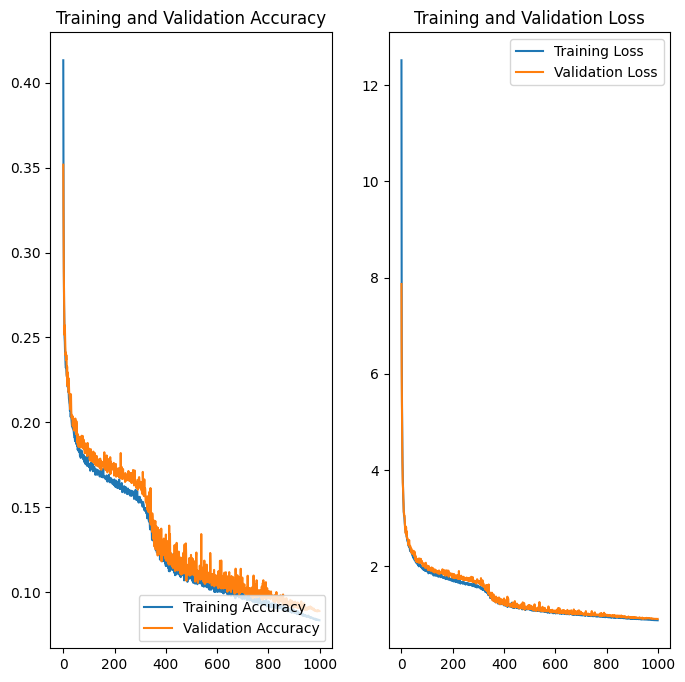

In [30]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

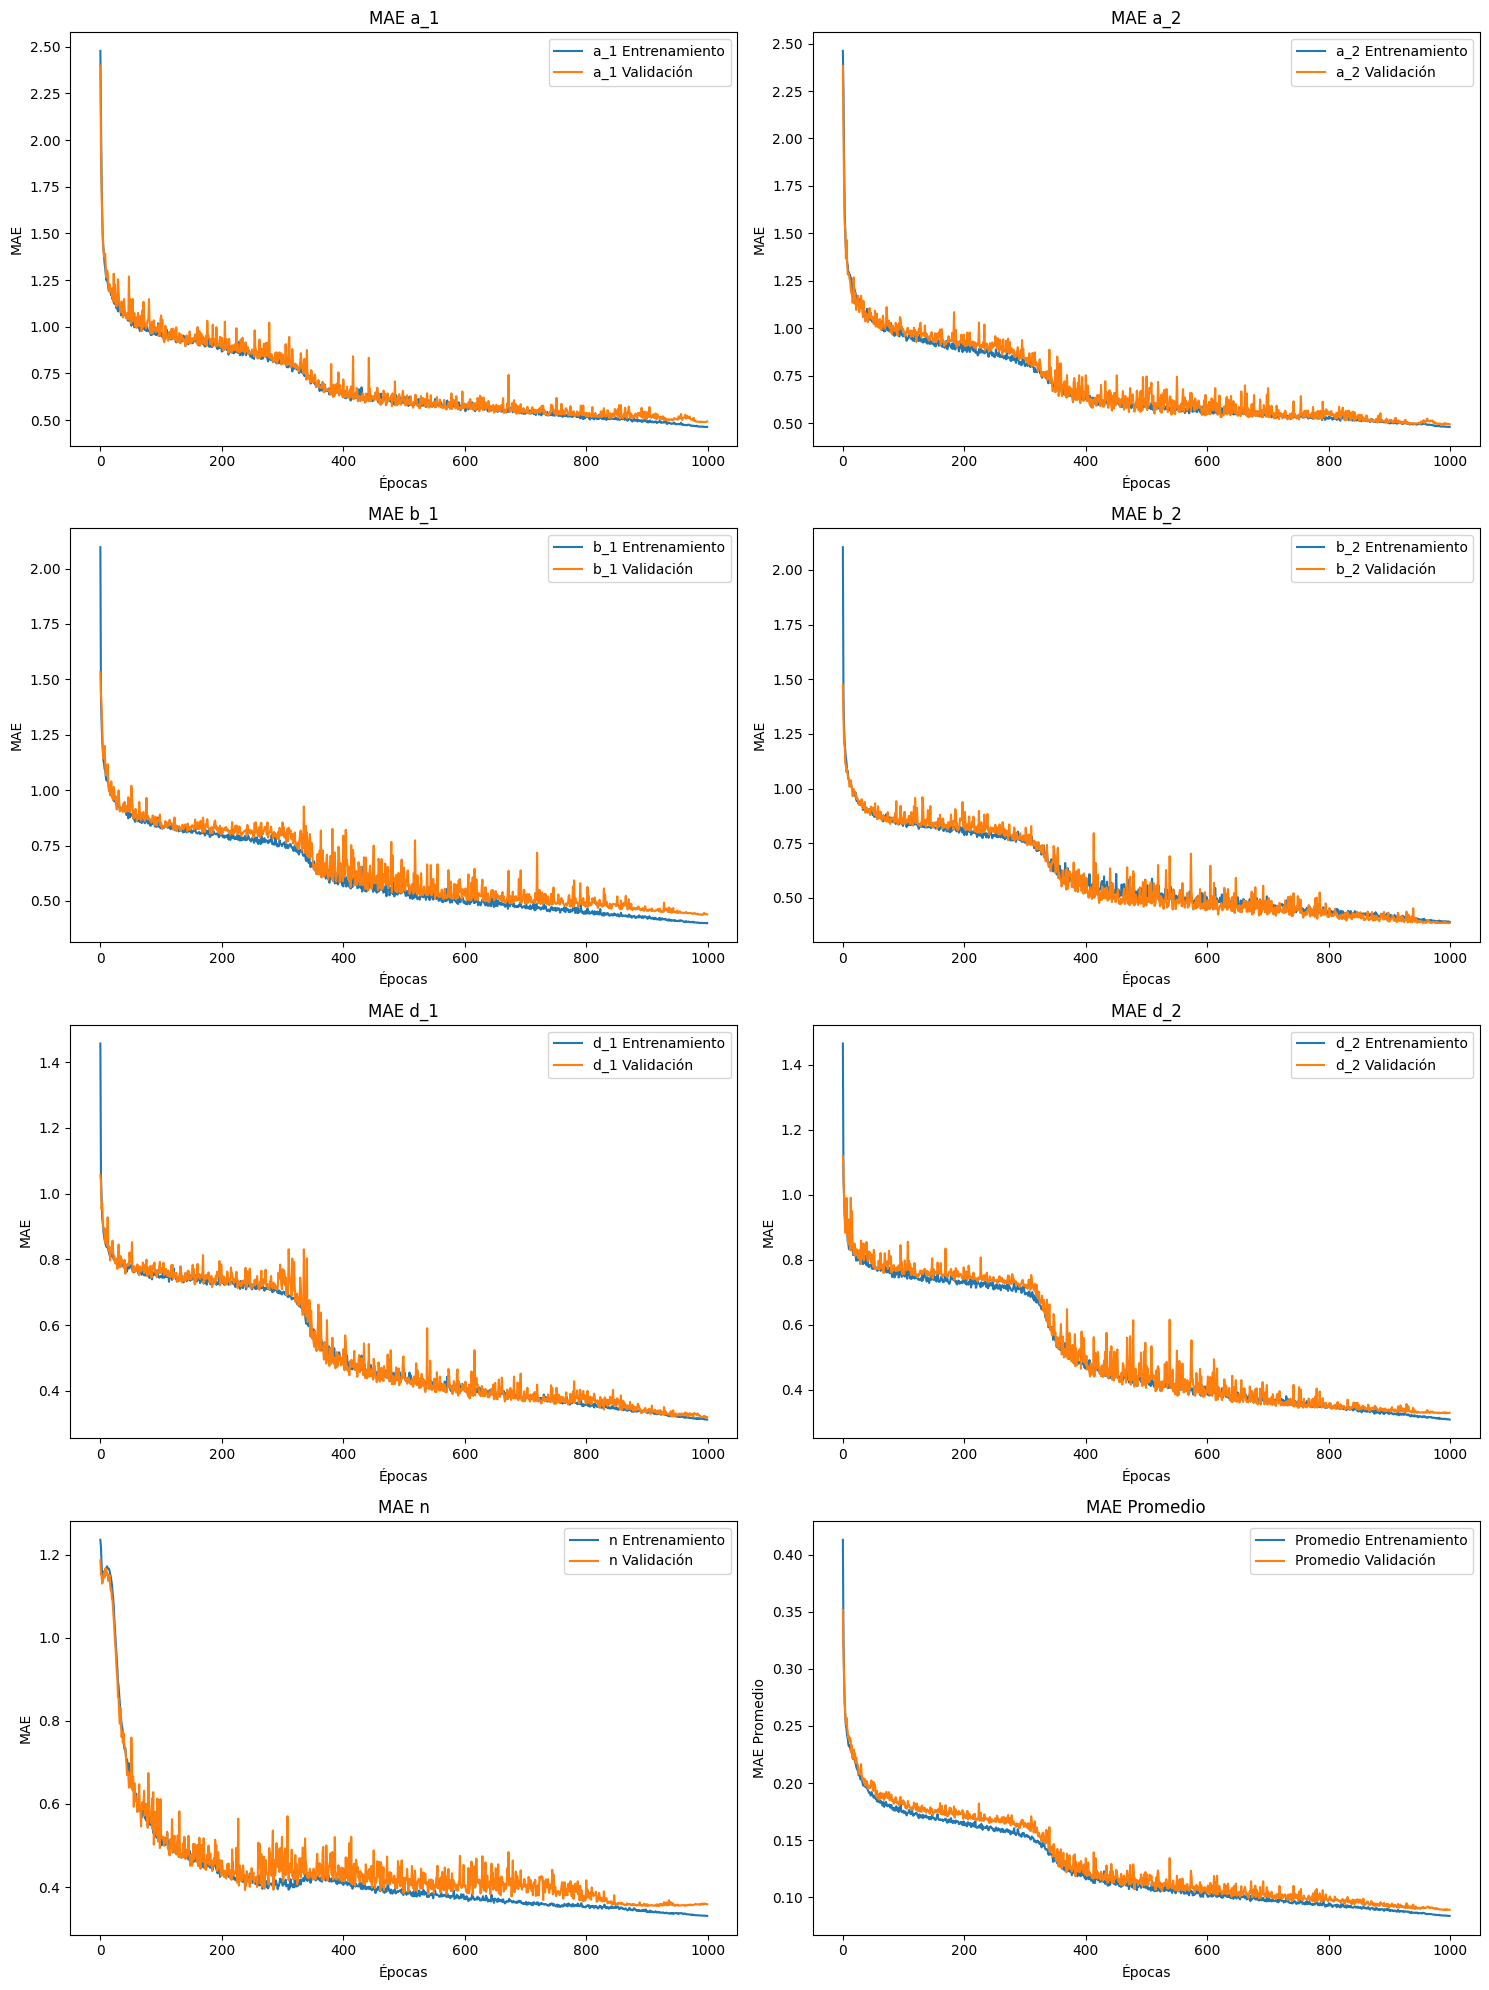

In [31]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [32]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 1s 6ms/step - loss: 0.8990 - a_1: 0.4788 - a_2: 0.4850 - b_1: 0.4227 - b_2: 0.4006 - d_1: 0.3275 - d_2: 0.3198 - n: 0.3602 - mean_metric: 0.0864


In [33]:
predictions = model.predict(campvectest)

63/63 [==============================] - 0s 4ms/step


In [34]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[ 4  5  0  1  7 10  3]
[3.5773315  5.2450747  0.79124284 1.2628319  7.1627626  9.015572
 2.220645  ]
[30 33 23 ... 21 35 40]


0.5211948667253766

In [35]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.3996810824062143, Desviación estándar del error: 0.5364166119610565, Error absoluto máximo: 3.613532543182373


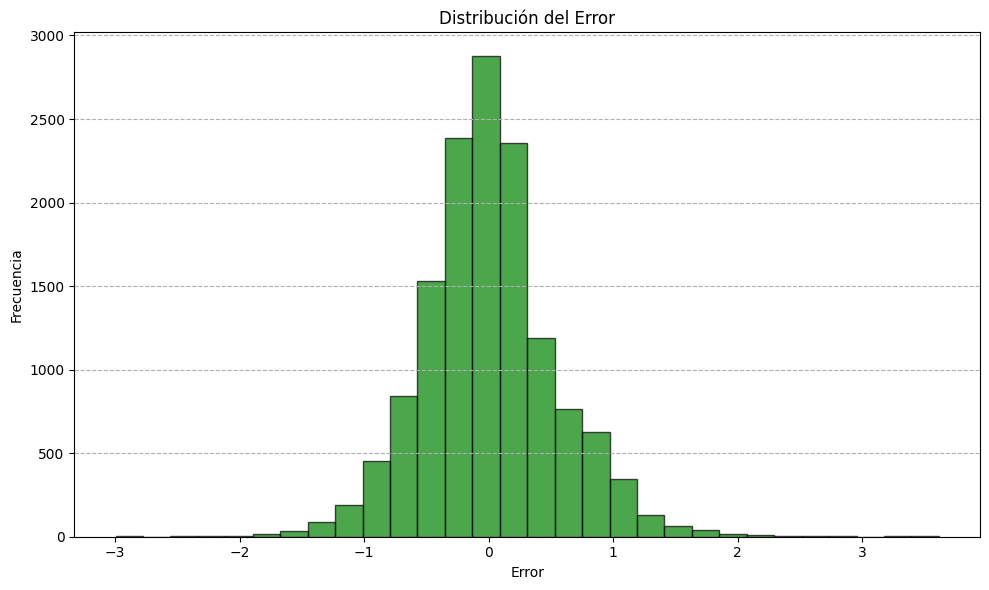

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [37]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.0873242676592665
Desviación estándar del error relativo: 0.052243094632639084
Error absoluto máximo relativo: 0.3948954403400421


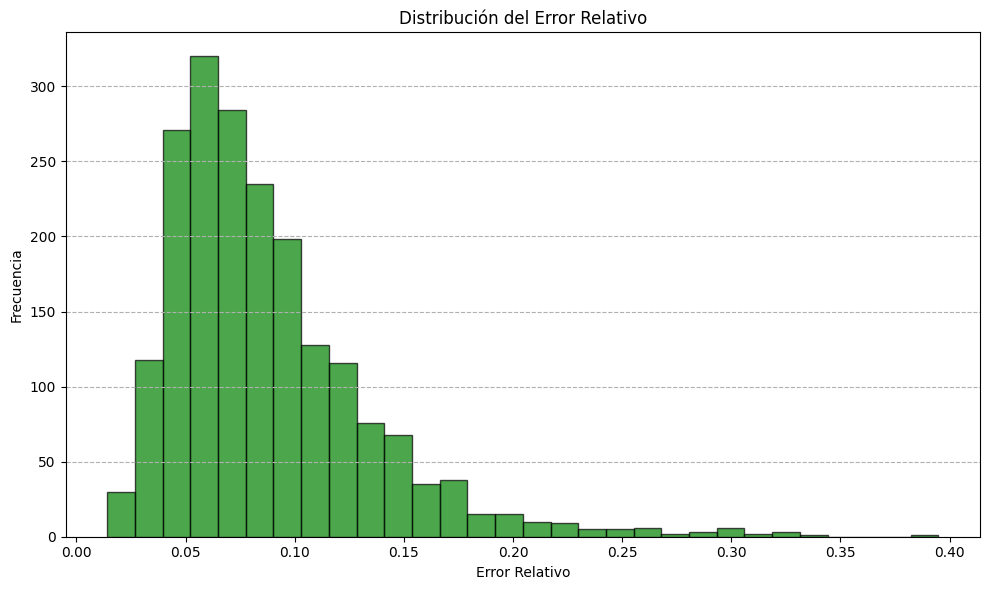

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()


# Guardamos los datos de Accuracy y Loss

In [39]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales con ruido/grid100_traj200/historyconvcampvec100.csv', index=False)

# Guardamos el modelo

In [40]:
path_to_save = '../../../trained_models_noisy/grid100_traj200/'

In [41]:
model.save(path_to_save + '/convolucionalcv100.h5')

# Importamos el modelo

In [1]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [2]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [3]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)

C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.1
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [4]:
import keras
import tensorflow as tf
new_model = keras.models.load_model('../../../trained_models_noisy/grid100_traj200/convolucionalcv100.h5', custom_objects=custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [5]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b1

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)

    t1 = 0

    NI, NJ = Y1.shape
    u, v = np.zeros((NI, NJ)), np.zeros((NI, NJ))

    for i in range(NI):
        for j in range(NJ):
            # asignar a cada ODE a un elemento de vector
            X = Y1[i, j]
            Y = Y2[i, j]
            noise1 = np.random.normal(0, .5)
            noise2 = np.random.normal(0, .5)

            # definimos cada ODE
            dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
            dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2

            u[i, j], v[i, j] = dX_dt, dY_dt
    
    u1,v1 = u,v
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[5, 7, 3, 1, 0, 2, 5]


In [6]:
campvecnone = campvec[None, :]
campvecnone = np.transpose(campvecnone, (0,2,3,1))

## Predecimos con los datos nuevos

In [7]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 121ms/step
[[5. 8. 3. 1. 0. 2. 5.]]


## Encontramos puntos de equilibro datos reales

In [8]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b1
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(-162.8940476722101, 1.8966918003352602)


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


## Graficamos con los coeficientes reales

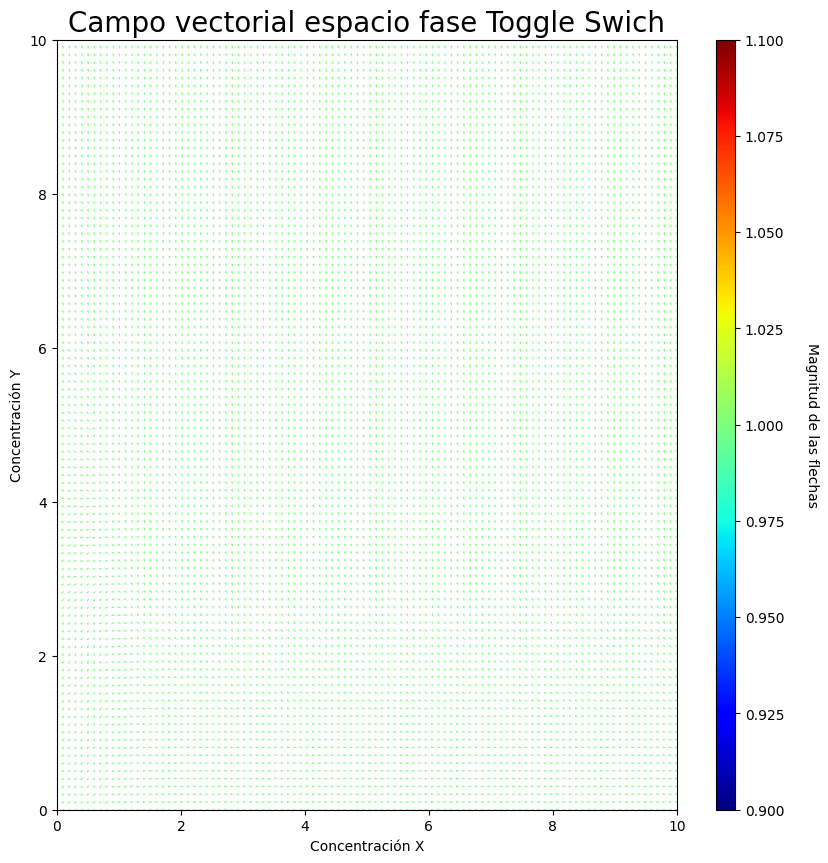

In [9]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values = primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 100)
y2 = np.linspace(0, 10, 100)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy', pivot='mid', cmap='jet')  # Añadir una cmap
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

cbar = plt.colorbar(Q, aspect=40, pad=0.05)  # Agregar la colorbar
cbar.set_label('Magnitud de las flechas', rotation=270, labelpad=25)

plt.show()

## Encontramos puntos de equilibro datos predecidos

In [10]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b1pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(-132.51310085860638, 1.896212125484732)


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

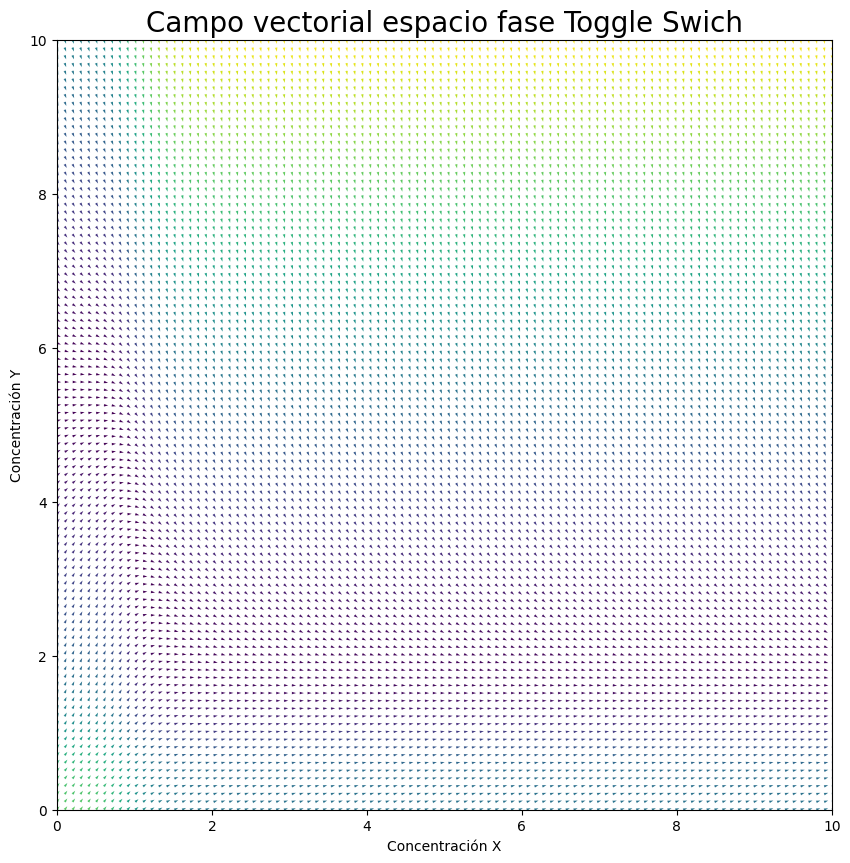

In [11]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b1pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 100)
y2pred = np.linspace(y_range_neg, y_range_pos, 100)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

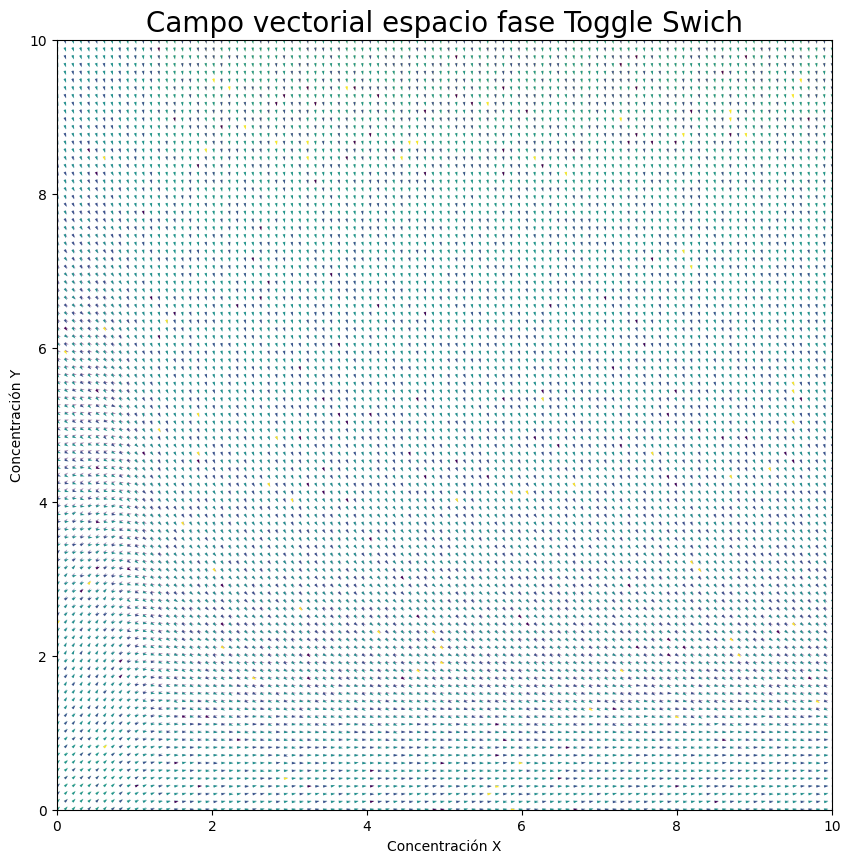

In [12]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

36.44826846132346


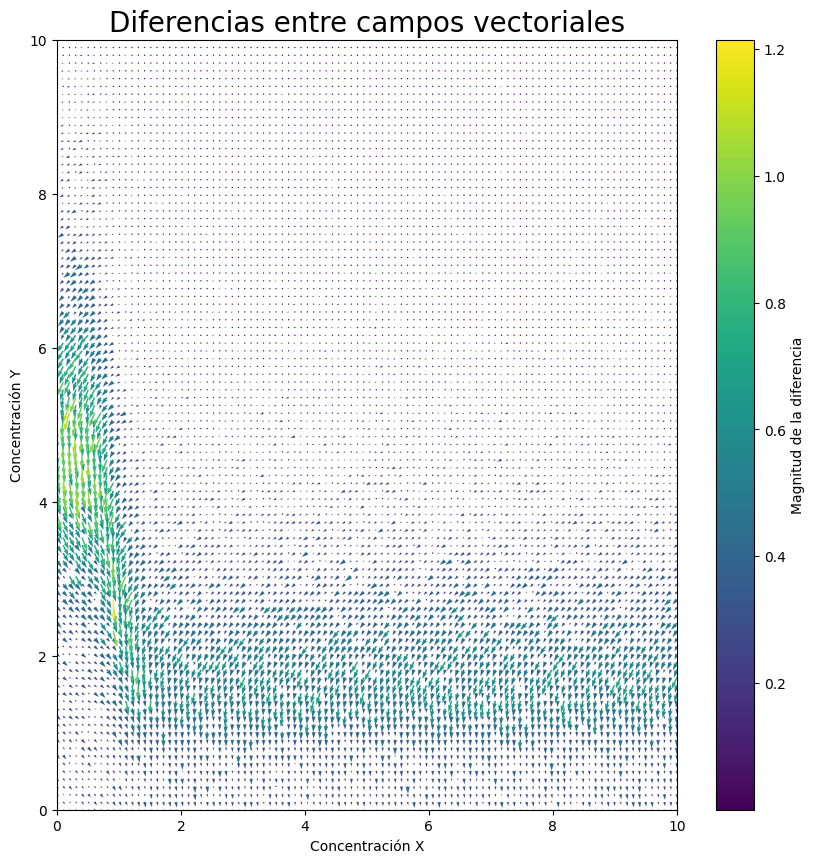

In [13]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

In [14]:
M_diff.mean()

0.18570379370943232

## Errores relativos

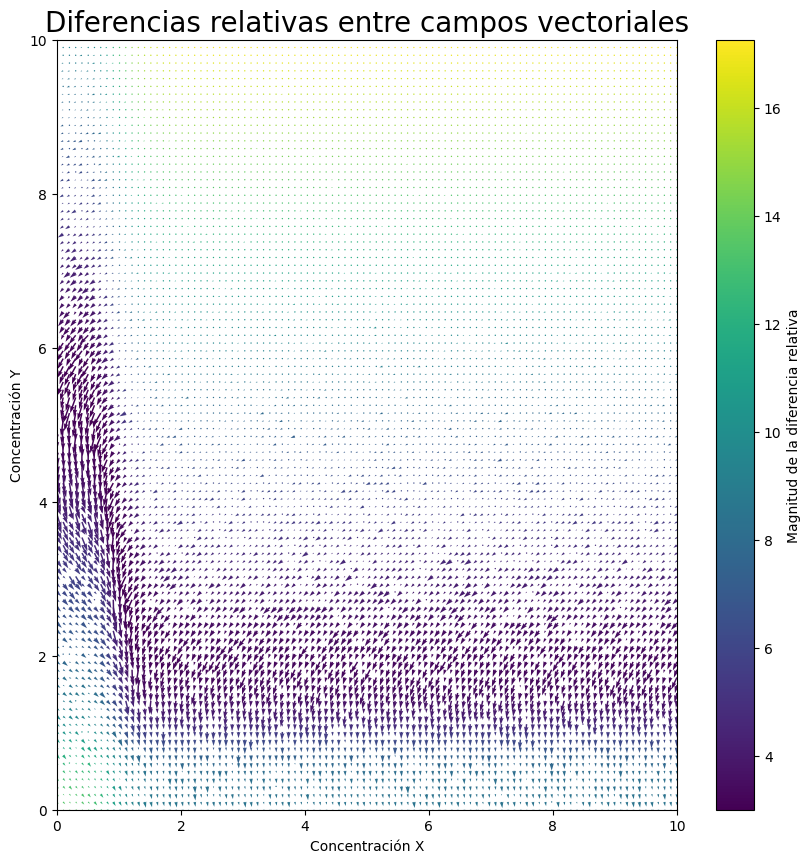

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [16]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 17.262604682769997
El valor de u1 en el error relativo máximo es: 0.16319515865232845
El valor de u1pred en el error relativo máximo es: 3.000049999500005
El valor de v1 en el error relativo máximo es: -0.9865938070920786
El valor de v1pred en el error relativo máximo es: -16.999920000799992


In [17]:
np.sqrt(u1pred[max_coords]**2+v1pred[max_coords]**2)/np.sqrt(u1[max_coords]**2+v1[max_coords]**2)

17.262606409030465

In [18]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 69.70%


In [6]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(1000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def ftrue(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape
    
    
    for i in range(NI):
        for j in range(NJ):
            # asignar a cada ODE a un elemento de vector
            X = Y1[i, j]
            Y = Y2[i, j]
            noise1 = np.random.normal(0, .5)
            noise2 = np.random.normal(0, .5)
            # definimos cada ODE
            dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
            dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2
            u[i, j], v[i, j] = dX_dt, dY_dt

    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 100)
    y2pred = np.linspace(y_range_neg, y_range_pos, 100)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred
    
    utrue, vtrue = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    utrue, vtrue = ftrue(t1, [Y1, Y2])
    Mtrue = (np.hypot(utrue, vtrue))
    utrue /= Mtrue
    vtrue /= Mtrue  

 # Calculamos las diferencias
    u_diff = utrue - upred
    v_diff = vtrue - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 5.62%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 6.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 12.44%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 32.37%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 0.00%
--------------------------------------------
1/1 [============================

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 16.80%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 44.15%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 7.44%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 27.17%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 9.78%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de pun

1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 75.73%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 63.07%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 4.85%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 49.17%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 3.26%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de pun

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 12.90%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 2.23%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 18.20%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 3.71%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 36.59%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 8.12%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 9.46%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 20.18%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 46.24%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje d

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 19.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 16.14%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 3.66%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 11.42%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje d

... (13 outputs left out)

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 837 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 838 es 41.28%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 839 es 32.74%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 840 es 20.33%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 841 es 34.22%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje 

1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 881 es 25.79%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 882 es 16.70%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 883 es 5.85%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 884 es 23.76%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 885 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porcentaje d

1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 925 es 15.97%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 926 es 12.74%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 927 es 10.58%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 928 es 23.45%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 929 es 4.51%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje 

1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 969 es 5.26%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 970 es 43.61%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 971 es 8.75%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 972 es 15.79%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 973 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de

El promedio de los porcentajes es 23.40%


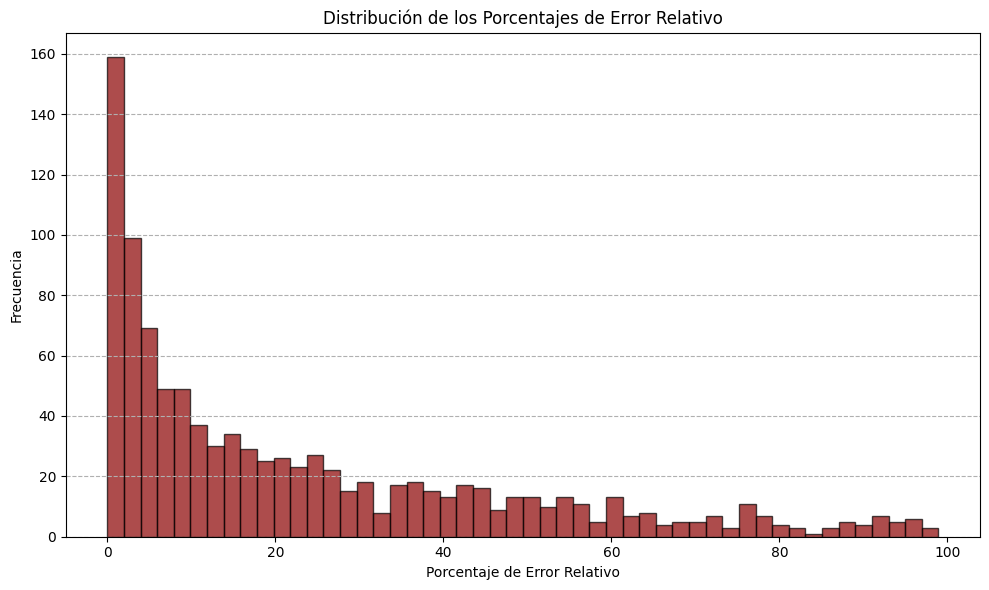

In [7]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()